# Drone RL — z and yaw with the thrust/speeds RNN

The default `rnn_model_thrust_speeds.pt` model takes `[thrust, roll, pitch, yaw]`
and predicts `[az, psi_ddot]`. `droneEnvRotation` uses `[thrust, 0, 0, yaw]`, then
integrates altitude z and yaw psi about the vertical z axis. `droneEnvGeneral`
is kept for later.

Run **Setup**, **Load the RNN**, **Choose a mission**, and **Plot helpers** first.
Then train PPO or run a **Results** cell with a policy trained for this model.
New policies use separate checkpoint paths. `SKIP_DQN` / `SKIP_SAC` default to
`True`, so Run All trains PPO only. Choose the mission before creating environments.
Training, evaluation, and plots use the selected mission.


## Setup


In [1]:
# Run once if needed, then restart the kernel:
# %pip install gymnasium stable-baselines3 numpy matplotlib scipy

import json
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import gymnasium as gym
from stable_baselines3 import PPO, DQN, SAC
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.results_plotter import load_results

PROJECT_ROOT = next(
    (candidate for directory in (Path.cwd(), *Path.cwd().parents)
     for candidate in (directory, directory / "EI-DATA-DRIVEN-CONTROL")
     if (candidate / "src/model/rnn_loader.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from this project or src/policy/notebooks/ to find src/model/rnn_loader.py")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
# Use "z" for the previous altitude-only model.
RNN_VARIANT = "thrust_speeds"
if RNN_VARIANT == "thrust_speeds":
    from policy.lib.droneEnvRotation import DroneEnv, PARAMS, Z_LAND, default_mission, run_episode, evaluate
elif RNN_VARIANT == "z":
    from policy.lib.droneEnv import DroneEnv, PARAMS, Z_LAND, default_mission, run_episode, evaluate
else:
    raise ValueError("RNN_VARIANT must be 'thrust_speeds' or 'z'")
from model.rnn_loader import load_rnn_model
from policy.evaluation import training_step_offset
from policy.training import (
    CurriculumCallback, configured_checkpoint, load_ppo_config,
    train_off_policy, train_ppo,
)

from stable_baselines3.common.callbacks import EvalCallback

PPO_CONFIG_PATH = PROJECT_ROOT / "src/policy/config/ppo.json"
PPO_CONFIG = load_ppo_config(PPO_CONFIG_PATH)
DQN_CONFIG = json.loads(PPO_CONFIG_PATH.with_name("dqn.json").read_text())
SAC_CONFIG = json.loads(PPO_CONFIG_PATH.with_name("sac.json").read_text())
SEED = PPO_CONFIG["seed"]
# Starting height index for z-only PPO; SAC uses its JSON curriculum setting.
CURRICULUM_DIFFICULTY = 0
# Skip both training and results for these algorithms during Run All.
SKIP_DQN = True
SKIP_SAC = True
torch.set_num_threads(1)
# Saved results: edit one path to inspect a different checkpoint.
MODEL_PATH = PROJECT_ROOT / "src" / "policy" / "checkpoints" / ("ppo_drone_thrust_speeds.zip" if RNN_VARIANT == "thrust_speeds" else "ppo_drone_rnn.zip")
PPO_MODEL_PATH = MODEL_PATH
DQN_MODEL_PATH = PROJECT_ROOT / (
    "src/policy/checkpoints/dqn_drone_thrust_speeds.zip" if RNN_VARIANT == "thrust_speeds"
    else "src/policy/logs/tuning_dqn_multistep_20261103_163054/best_model.zip"
)
SAC_MODEL_PATH = ((configured_checkpoint(SAC_CONFIG) or configured_checkpoint(SAC_CONFIG, "initial_checkpoint")) if RNN_VARIANT == "z"
                  else PROJECT_ROOT / "src/policy/checkpoints/sac_drone_thrust_speeds.zip")

# New training runs get separate folders; plotting does not create or require them.
RUN_DIR = PROJECT_ROOT / "results" / "altitude_psi" / f"notebook_{time.strftime('%Y%m%d_%H%M%S')}"
LOG_DIR = RUN_DIR / "export"
PPO_DIR = RUN_DIR / "ppo"
PPO_STEPS = PPO_CONFIG["total_timesteps"]
PPO_PARAMS = dict(PPO_CONFIG["ppo"])
PPO_INITIAL_LOG_STD = PPO_CONFIG["initial_log_std"]
DQN_DIR = RUN_DIR / "dqn"
DQN_STEPS = DQN_CONFIG["total_timesteps"]
DQN_PARAMS = dict(DQN_CONFIG["dqn"])
SAC_DIR = RUN_DIR / "sac"
SAC_STEPS = SAC_CONFIG["total_timesteps"]
SAC_PARAMS = dict(SAC_CONFIG["sac"])


## Load the trained RNN and head

`RNN_VARIANT="thrust_speeds"` selects
`src/model/checkpoints/rnn_model_thrust_speeds.pt`: a 4-input, 64-hidden-unit,
one-layer RNN with a linear 64 → 2 head. `rnn_loader` loads all weights strictly.

Before normalization, actions expand to `[thrust, 0, 0, yaw]` in training order
`[thrust, roll, pitch, yaw]`. The environment keeps the supplied means/stds:
`[-0.0205, 0.0014, 0, 0]` / `[6.4559, 0.4590, 0, 0]`. Zero standard deviations use a scale of 1 to avoid division by zero. Outputs `[az, psi_ddot]` use
`[-9.9011, 0.0310]` / `[20.6719, 10.7658]`. Predictions are denormalized and
integrated directly. Each environment keeps its own recurrent hidden state.

Set `RNN_VARIANT="z"` for the previous altitude environment and `rnn_z` checkpoint.


In [2]:
model_path = PROJECT_ROOT / "src" / "model" / "checkpoints" / (
    "rnn_model_thrust_speeds.pt" if RNN_VARIANT == "thrust_speeds" else "rnn_z"
)
acceleration_rnn = load_rnn_model(model_path)

print("Model:", model_path)
print("Load: all checkpoint weights matched")
print("RNN:", acceleration_rnn.rnn)
print("Head:", acceleration_rnn.head)


Model: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/src/model/checkpoints/rnn_model_thrust_speeds.pt
Load: all checkpoint weights matched
RNN: RNN(4, 64, batch_first=True)
Head: Linear(in_features=64, out_features=2, bias=True)


## Choose a mission

Edit `ref_mission(t)` below. All environments use it for training and evaluation.
The mission climbs to 2 m, turns 360° about z, then requests landing.
Rotation references are `(z_ref, psi_ref)`; pitch and roll remain zero
for this model. Yaw stays unwrapped so a full turn differs from no turn.
Rerun this cell and recreate environments after editing it.

The policy observes `[z-z_ref, vz, az, psi-psi_ref, wz, wz_dot]`. The current
reference enters through tracking errors; future targets are not policy inputs.


In [ ]:
def ref_mission(t):
    """Climb to 2 m, turn once around z, then land holding the final yaw."""
    if RNN_VARIANT == "z":
        return 0.0 if t < 2.0 else (2.0 if t < 6.0 else Z_LAND)
    if t < 2.0:
        return (0.0, 0.0)
    elif t < 5.0:
        return (2.0, 0.0)
    elif t < 10.0:
        return (2.0, float(2.0 * np.pi * (t - 5.0) / 5.0))
    else:
        return (Z_LAND, float(2.0 * np.pi))


## Plot helpers

Shared action wrappers and plotting functions; this cell does not train or load a policy.


In [4]:
DQN_COMMANDS = np.linspace(
    DQN_CONFIG["action_grid"]["low"], DQN_CONFIG["action_grid"]["high"],
    DQN_CONFIG["action_grid"]["count"], dtype=np.float32,
)

if RNN_VARIANT == "thrust_speeds":
    # Each discrete action chooses both thrust and yaw.
    thrust, yaw = np.meshgrid(DQN_COMMANDS, np.linspace(-3.0, 3.0, 9), indexing="ij")
    DQN_COMMANDS = np.column_stack([thrust.ravel(), yaw.ravel()]).astype(np.float32)

class DiscreteDroneActions(gym.ActionWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.action_space = gym.spaces.Discrete(len(DQN_COMMANDS))

    def action(self, index):
        return np.atleast_1d(DQN_COMMANDS[int(index)]).astype(np.float32)

def show_result(name, checkpoint, mission_to_test = None):
    if callable(checkpoint):
        learned_policy = checkpoint
        model = None
        checkpoint = None
    else:
        checkpoint = Path(checkpoint)
        load_kwargs = {"replay_buffer_class": None} if name == "DQN" else {}
        model = {"PPO": PPO, "DQN": DQN, "SAC": SAC}[name].load(checkpoint, device="cpu", **load_kwargs)
        commands = np.load(checkpoint.parent / "commands.npy") if name == "DQN" else None

        def learned_policy(obs):
            action = model.predict(obs, deterministic=True)[0]
            return np.atleast_1d(commands[int(action)]).astype(np.float32) if commands is not None else action

    if mission_to_test is not None:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=mission_to_test)
    else:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
    if model is not None:
        print(f"{name}: {checkpoint} ({model.num_timesteps:,} training steps)")
    else:
        print(f"{name}: heuristic controller")
    states, actions, total, outcome = run_episode(eval_env, learned_policy, seed=100)
    base = eval_env.unwrapped
    mission = base.mission
    t = np.arange(len(states)) * base.p.dt
    u = np.asarray(actions).reshape(len(actions), -1)
    targets = np.asarray([mission(float(ti)) for ti in t])
    z_target = targets if targets.ndim == 1 else targets[:, 0]
    has_psi = states.shape[1] > 11
    mae = np.mean(np.abs(states[1:, 0] - z_target[1:]))
    rms_du = np.sqrt(np.mean(np.diff(np.vstack([np.zeros((1, u.shape[1])), u]), axis=0) ** 2))
    status = ", ".join(outcome) if isinstance(outcome, tuple) else outcome
    print(f"{name}: {status} at {t[-1]:.2f} s | return {total:.1f} | "
          f"MAE {mae:.3f} m | peak altitude {states[:, 0].max():.3f} m | "
          f"final vz {states[-1, 1]:.3f} m/s | RMS delta-u {rms_du:.3f}")
    if has_psi:
        print(f"Final psi: {states[-1, 11]:.3f} rad ({np.degrees(states[-1, 11]):.1f} deg)")
    horizon = base.max_steps * base.p.dt
    duration = t[-1]
    end = min(horizon, duration + 0.25) if duration < 2.0 else horizon
    fig, axes = plt.subplots(4 if has_psi else 3, 1,
                             figsize=(9, 9 if has_psi else 7), sharex=True)
    mask = t <= end
    line, = axes[0].plot(t[mask], states[mask, 0], label=f"{name}: {status} at {t[-1]:.2f} s")
    color = line.get_color()
    axes[1].plot(t[mask], states[mask, 1], color=color)
    final_values = [states[-1, 0], states[-1, 1]]
    ylabels = ["Altitude z (m)", "Velocity vz (m/s)"]
    if has_psi:
        axes[2].plot(t[mask], states[mask, 11], color=color, label="Environment psi")
        final_values.append(states[-1, 11])
        ylabels.append("Yaw psi (rad)")
    padded_u = np.vstack([u, u[-1:]])
    command_labels = ["thrust", "yaw"] if u.shape[1] == 2 else [f"u{i + 1}" for i in range(u.shape[1])]
    for channel, label in enumerate(command_labels):
        command_line, = axes[-1].step(t[mask], padded_u[mask, channel],
                                      where="post", label=label)
        if t[-1] <= end:
            axes[-1].plot(t[-1], u[-1, channel], "x", color=command_line.get_color())
    if u.shape[1] > 1:
        axes[-1].legend(fontsize=8)
    if t[-1] <= end:
        for ax, value in zip(axes[:-1], final_values):
            ax.plot(t[-1], value, "x", color=color)
        for ax in axes:
            ax.axvline(t[-1], color=color, linestyle=":", alpha=0.4)
    reference_t = np.arange(0, end + base.p.dt / 2, base.p.dt)
    reference = np.asarray([mission(float(ti)) for ti in reference_t])
    z_reference = reference if reference.ndim == 1 else reference[:, 0]
    axes[0].step(reference_t, z_reference, where="post",
                 color="black", linestyle="--", label="Mission target")
    if has_psi:
        # Rotation missions track only (z, psi).
        axes[2].plot(reference_t, reference[:, 1], color="black", linestyle="--",
                     label="Mission psi target")
        axes[2].legend(fontsize=8)
    ylabels.append("Command u")
    for ax, ylabel in zip(axes, ylabels):
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].set_title(f"{name} — saved policy" if model is not None else name)
    axes[0].legend(fontsize=8)
    axes[-1].set(xlabel="Time (s)", xlim=(0, end))
    fig.tight_layout()
    plt.show()
    eval_env.close()

    if checkpoint is not None and list(checkpoint.parent.glob("*.monitor.csv")):
        history = load_results(str(checkpoint.parent))
        returns = history["r"].to_numpy()
        steps = history["l"].cumsum().to_numpy() + training_step_offset(checkpoint.parent)
        window = min(20, len(returns))
        fig, ax = plt.subplots(figsize=(9, 3))
        if window:
            ax.plot(steps[window - 1:], np.convolve(returns, np.ones(window) / window, "valid"),
                    label=f"Training: mean over {window} episodes", alpha=0.7)
        evaluation_file = checkpoint.parent / "evaluations.npz"
        if evaluation_file.is_file():
            with np.load(evaluation_file) as evaluations:
                ax.plot(evaluations["timesteps"], evaluations["results"].mean(axis=1),
                        marker=".", label="Deterministic evaluation")
        ax.axvline(model.num_timesteps, color="black", linestyle=":", label="Loaded checkpoint")
        ax.set(title=f"{name} learning curve", xlabel="Environment steps", ylabel="Episode return")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()

## Heuristic — simple RNN input/output test

Edit the table below: up, neutral thrust, turn, down, turn the other way.
The RNN receives `[thrust, 0, 0, yaw]` with the exact environment normalization.
The middle plots are its raw denormalized acceleration predictions; the bottom
plots integrate them with the same timestep. No mission, optimizer or RL is used.

Neutral thrust means approximately zero vertical acceleration; it does not
hold altitude or cancel existing velocity. This runs all phases directly through
the RNN, without stopping at the environment's ground/ceiling boundaries.


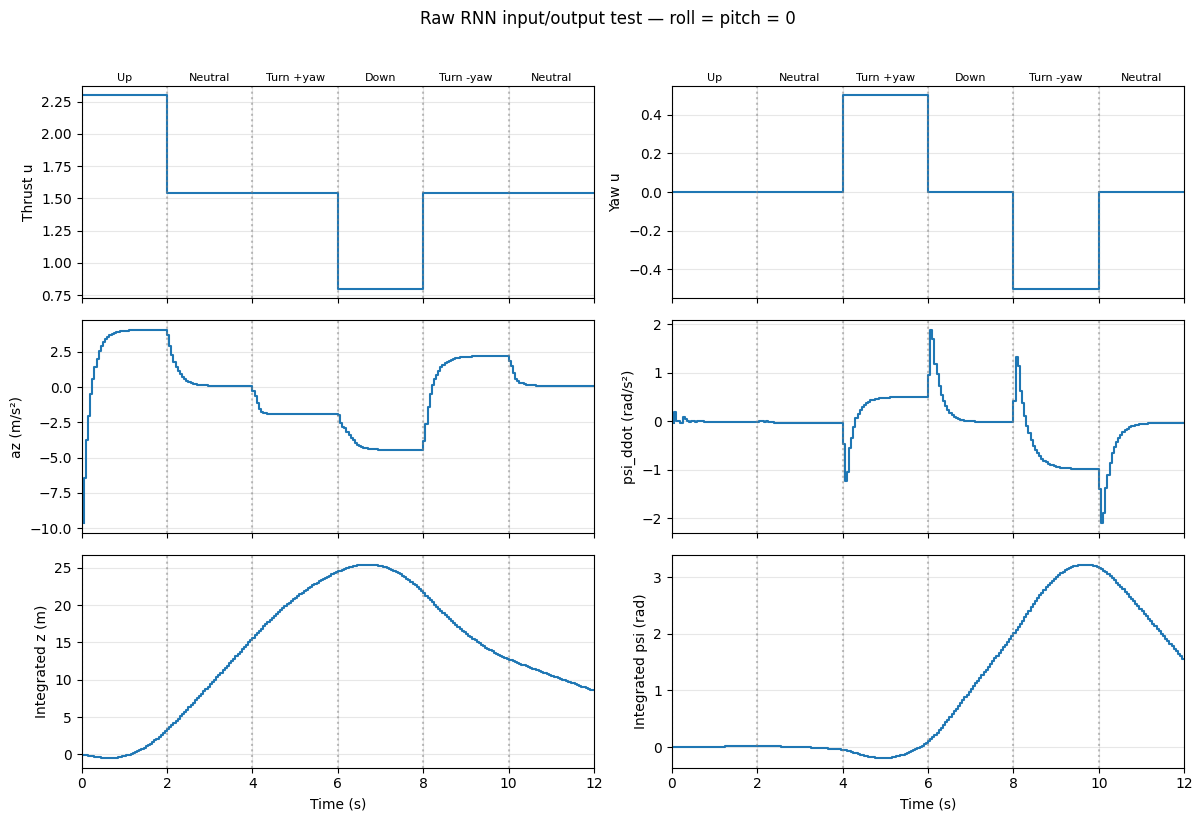

Up         thrust=2.30, yaw=+0.00: mean az=+2.64, mean psi_ddot=-0.00
Neutral    thrust=1.54, yaw=+0.00: mean az=+0.50, mean psi_ddot=-0.03
Turn +yaw  thrust=1.54, yaw=+0.50: mean az=-1.80, mean psi_ddot=+0.28
Down       thrust=0.80, yaw=+0.00: mean az=-4.12, mean psi_ddot=+0.23
Turn -yaw  thrust=1.54, yaw=-0.50: mean az=+1.53, mean psi_ddot=-0.62
Neutral    thrust=1.54, yaw=+0.00: mean az=+0.24, mean psi_ddot=-0.32


In [5]:
# (phase name, thrust, yaw); roll and pitch always remain zero.
io_phases = [
    ("Up", 2.3, 0.0),
    ("Neutral", 1.54, 0.0),
    ("Turn +yaw", 1.54, 0.5),
    ("Down", 0.8, 0.0),
    ("Turn -yaw", 1.54, -0.5),
    ("Neutral", 1.54, 0.0),
]
phase_seconds, dt = 2.0, PARAMS.dt
phase_steps = round(phase_seconds / dt)
io_commands = np.repeat(np.array([phase[1:] for phase in io_phases], dtype=np.float32), phase_steps, axis=0)
io_inputs = np.zeros((len(io_commands), 4), dtype=np.float32)
io_inputs[:, [0, 3]] = io_commands  # [thrust, roll=0, pitch=0, yaw]
scale = np.where(PARAMS.sigma_u == 0, 1.0, PARAMS.sigma_u)
with torch.no_grad():
    io_prediction, _ = acceleration_rnn(torch.from_numpy((io_inputs - PARAMS.mean_u) / scale)[None], None)
io_acceleration = io_prediction[0].numpy() * [PARAMS.sigma_az, PARAMS.sigma_wz_dot] + [PARAMS.mean_az, PARAMS.mean_wz_dot]
io_velocity = np.cumsum(io_acceleration, axis=0) * dt
io_position = np.cumsum(io_velocity, axis=0) * dt
io_t = (np.arange(len(io_commands)) + 1) * dt

io_fig, io_axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
io_series = [io_commands[:, 0], io_commands[:, 1], io_acceleration[:, 0],
             io_acceleration[:, 1], io_position[:, 0], io_position[:, 1]]
io_labels = ["Thrust u", "Yaw u", "az (m/s²)", "psi_ddot (rad/s²)", "Integrated z (m)", "Integrated psi (rad)"]
for ax, values, label in zip(io_axes.flat, io_series, io_labels):
    ax.step(io_t, values, where="pre")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
    for i, (name, _, _) in enumerate(io_phases):
        ax.axvline(i * phase_seconds, color="grey", linestyle=":", alpha=0.5)
        if ax in io_axes[0]:
            ax.text((i + 0.5) * phase_seconds, 1.02, name, ha="center", fontsize=8, transform=ax.get_xaxis_transform())
for ax in io_axes[-1]:
    ax.set(xlabel="Time (s)", xlim=(0, io_t[-1]))
io_fig.suptitle("Raw RNN input/output test — roll = pitch = 0", y=1.02)
io_fig.tight_layout()
IO_DIR = RUN_DIR / "heuristic_io"
IO_DIR.mkdir(parents=True, exist_ok=True)
io_fig.savefig(IO_DIR / "input_output.png", dpi=150, bbox_inches="tight")
np.savez(IO_DIR / "input_output.npz", t=io_t, inputs=io_inputs, acceleration=io_acceleration, velocity=io_velocity, position=io_position)
plt.show()
for i, (name, thrust, yaw) in enumerate(io_phases):
    az, psi_ddot = io_acceleration[i * phase_steps:(i + 1) * phase_steps].mean(axis=0)
    print(f"{name:10s} thrust={thrust:.2f}, yaw={yaw:+.2f}: mean az={az:+.2f}, mean psi_ddot={psi_ddot:+.2f}")


## Optional environment check


In [6]:
env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
check_env(env)
obs, info = env.reset(seed=SEED)
print("Observation:", obs, env.observation_space)
print("Action:", env.action_space)
print("check_env: OK")
env.close()


Observation: [ 0.     0.    -9.816  0.     0.     0.   ] Box([ -10.  -20. -100.  -inf  -inf -500.], [ 10.  20. 100.  inf  inf 500.], (6,), float32)
Action: Box(-3.0, 3.0, (2,), float32)
check_env: OK


/home/rayan768/venvs/main_env/lib/python3.13/site-packages/stable_baselines3/common/env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


## PPO — optional training

Settings come from `src/policy/config/ppo.json`. This cell uses the same
training function as `main_z.py` and saves TensorBoard logs and the resolved
config under `PPO_DIR`.

For curriculum training, set `RNN_VARIANT="z"` in Setup.
`CURRICULUM_DIFFICULTY` is the starting index in `[0.5, 1, 2, 5, 10]`;
set it to `None` for the fixed mission. The callback advances modulo 5 after
at least 85% success over 20 completed episodes at the current height.
Success means reaching the target within 0.2 m, then landing softly.
Timing stays 0 m until 2 s, hover until 6 s, then land (10 s deadline).
Difficulty changes apply at episode resets. Evaluation stays on `ref_mission`.
The final curriculum checkpoint is selected; TensorBoard logs `curriculum/*`.


In [7]:
ppo_curriculum = (
    CurriculumCallback(difficulty=CURRICULUM_DIFFICULTY, verbose=1)
    if RNN_VARIANT == "z" and CURRICULUM_DIFFICULTY is not None else None
)
start = time.perf_counter()
agent, PPO_MODEL_PATH = train_ppo(
    acceleration_rnn,
    ref_mission,
    PPO_DIR,
    total_timesteps=PPO_STEPS,
    seed=SEED,
    env_class=DroneEnv,
    initial_log_std=PPO_INITIAL_LOG_STD,
    config_path=PPO_CONFIG_PATH,
    curriculum=ppo_curriculum,
    **PPO_PARAMS,
)
print(f"PPO: {agent.num_timesteps:,}-step checkpoint; {time.perf_counter() - start:.1f} s")
print("Checkpoint:", PPO_MODEL_PATH)
print("TensorBoard logs:", PPO_DIR / "tensorboard")


KeyboardInterrupt: 

## PPO — Results

Run this cell directly after the shared setup cells to load the saved PPO.


PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/altitude_psi/notebook_20261106_094625/ppo/best_model.zip (20,480 training steps)
PPO: crashed, no_turn at 0.25 s | return -1004.8 | MAE 0.163 m | peak altitude 0.000 m | final vz -2.242 m/s | RMS delta-u 0.125
Final psi: 0.020 rad (1.1 deg)


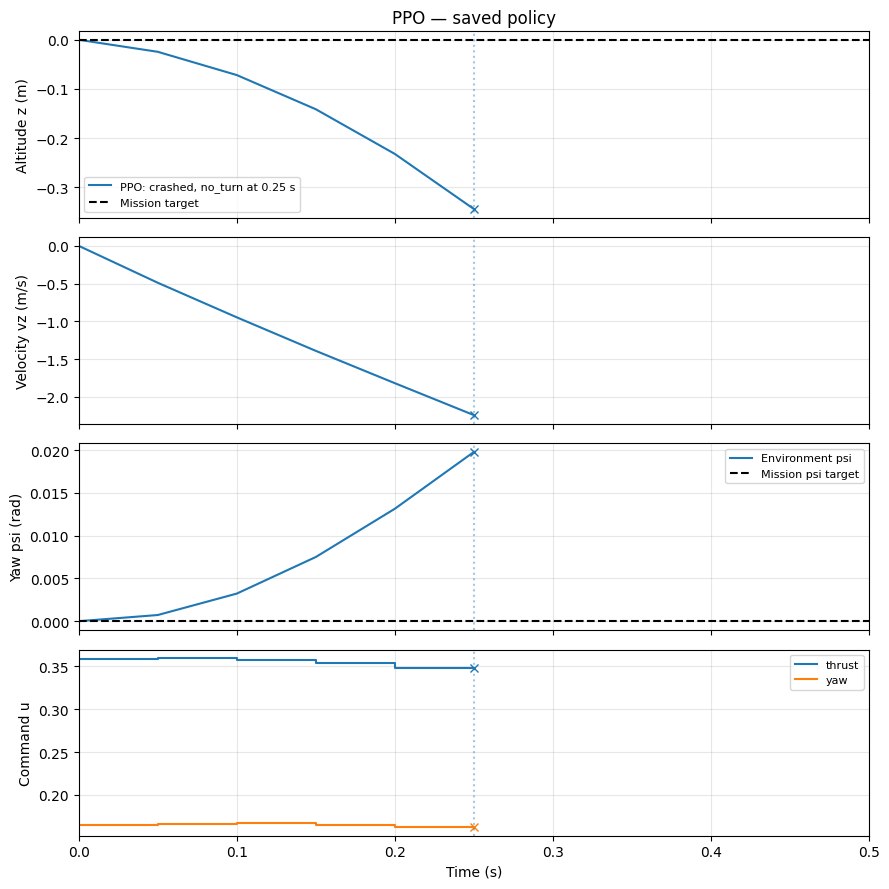

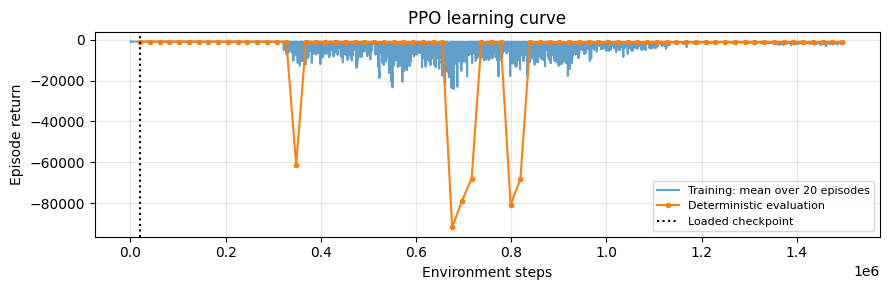

In [ ]:
show_result("PPO", PPO_MODEL_PATH)


In [ ]:
agent.save(MODEL_PATH)
print("Saved:", MODEL_PATH.with_suffix(".zip"))

# The existing MATLAB exporter handles the previous single-command model.
EXPORT_MATLAB = RNN_VARIANT == "z"
if EXPORT_MATLAB:
    from policy.export_policy import export_for_matlab
    export_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
    export_for_matlab(agent, export_env, output_dir=LOG_DIR)
    export_env.close()

Saved: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/src/policy/checkpoints/ppo_drone_thrust_speeds.zip


## Changing mission

In [ ]:
def test_mission(t):
    """Climb to 2 m and turn in the opposite direction around z."""
    if RNN_VARIANT == "z":
        return 0.0 if t < 2.0 else (2.0 if t < 5.0 else Z_LAND)
    if t < 2.0:
        return (0.0, 0.0)
    elif t < 5.0:
        return (2.0, 0.0)
    elif t < 8.0:
        return (2.0, float(-2.0 * np.pi * (t - 5.0) / 3.0))
    else:
        return (Z_LAND, float(-2.0 * np.pi))


PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/altitude_psi/notebook_20261106_094625/ppo/best_model.zip (20,480 training steps)
PPO: crashed, no_turn at 0.25 s | return -1004.8 | MAE 0.163 m | peak altitude 0.000 m | final vz -2.242 m/s | RMS delta-u 0.125
Final psi: 0.020 rad (1.1 deg)


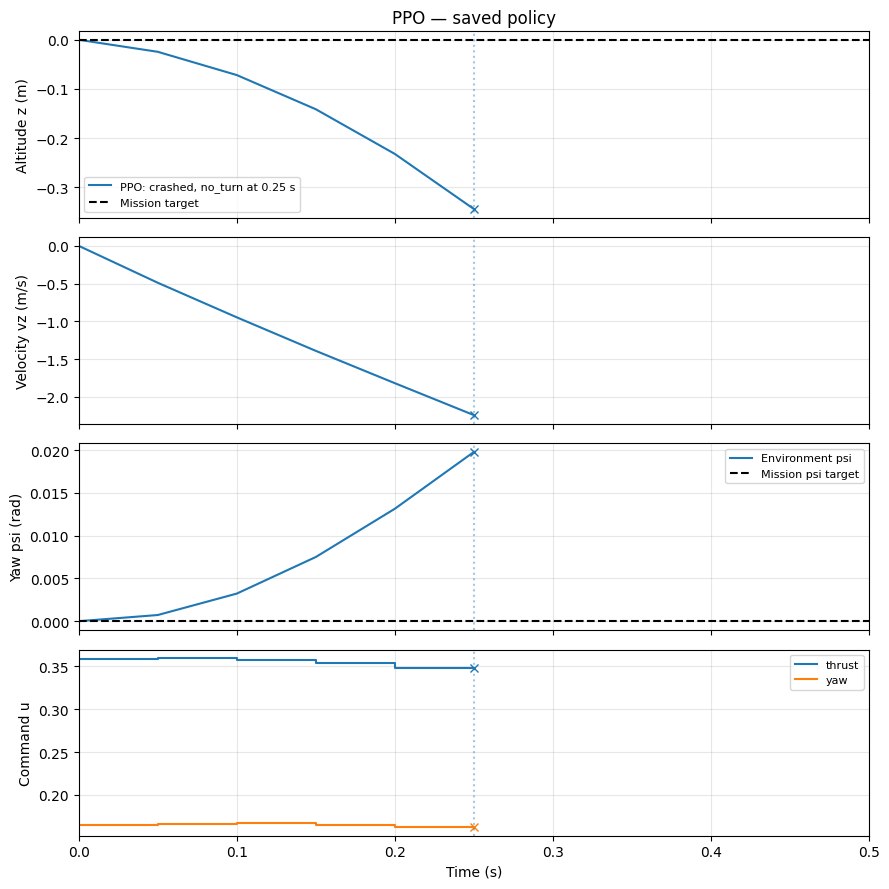

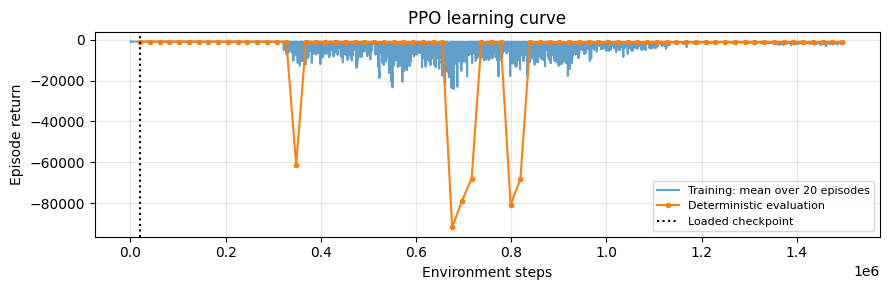

In [ ]:
show_result("PPO", PPO_MODEL_PATH, mission_to_test=test_mission)

## DQN — optional training

Skipped when `SKIP_DQN=True` in Setup.

Use 61 thrust commands across `[-3.0, 3.0]` and, for the rotation model,
nine yaw commands across `[-3.0, 3.0]`. Each action selects a `(thrust, yaw)`
pair so DQN can climb and turn. The altitude model keeps scalar commands.
The exact table is saved as `commands.npy` and reloaded by the Results cell.

Training settings and the command grid are loaded from `src/policy/config/dqn.json`.
The successful DQN settings use `n_steps=3`, `tau=0.1`, and `train_freq=5`.
With `gradient_steps=-1`, 50 transitions are followed by 50 updates with 10 environments.

Sources: [DQN parameters](https://stable-baselines3.readthedocs.io/en/master/modules/dqn.html#parameters),
[multi-environment update guidance](https://stable-baselines3.readthedocs.io/en/master/guide/examples.html#multiprocessing-with-off-policy-algorithms).


In [ ]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    def make_dqn_env():
        env = DiscreteDroneActions(DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission))
        return env

    dqn_env = make_vec_env(make_dqn_env, n_envs=DQN_CONFIG["n_envs"], seed=DQN_CONFIG["seed"], monitor_dir=str(DQN_DIR))
    dqn_eval = make_vec_env(make_dqn_env, n_envs=1, seed=100)
    dqn_callback = EvalCallback(
        dqn_eval, best_model_save_path=str(DQN_DIR), log_path=str(DQN_DIR),
        eval_freq=max(1, DQN_CONFIG["eval_freq"] // DQN_CONFIG["n_envs"]), n_eval_episodes=1, deterministic=True, verbose=0,
    )
    dqn_agent = DQN("MlpPolicy", dqn_env, seed=DQN_CONFIG["seed"], device="cpu", verbose=0, **DQN_PARAMS)
    start = time.perf_counter()
    dqn_agent.learn(total_timesteps=DQN_STEPS, callback=dqn_callback)
    dqn_agent.save(DQN_DIR / "dqn_drone_rnn")
    np.save(DQN_DIR / "commands.npy", DQN_COMMANDS)
    DQN_MODEL_PATH = DQN_DIR / "best_model.zip"
    dqn_env.close()
    dqn_eval.close()
    print(f"DQN: {dqn_agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s; {DQN_MODEL_PATH}")


DQN skipped (SKIP_DQN=True).


## DQN — Results

Skipped when `SKIP_DQN=True` in Setup.

Loads only DQN and its saved `commands.npy`; PPO and SAC do not need to run.


In [ ]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    show_result("DQN", DQN_MODEL_PATH)


DQN skipped (SKIP_DQN=True).


## SAC — optional training

Skipped when `SKIP_SAC=True` in Setup.

Training uses `train_off_policy` from `policy.training`, just like `main_z.py`.
Settings and the starting checkpoint come from `src/policy/config/sac.json`.
The altitude baseline is `20261105_202000_ztol02/training/best_model.zip` at
327,680 steps. The 500,000-step target includes those existing steps.
The old zip has no replay buffer: training collects 2,000 fresh warmup
transitions before updates. The starting policy is evaluated and saved before
training, and remains selected unless a later evaluation improves its return.
Set `initial_checkpoint` to `null` in the config to train altitude SAC from scratch.
For `RNN_VARIANT="z"`, the configured altitude checkpoint is used.
Rotation training starts from scratch because its spaces differ.

SAC uses the environment's full continuous action space and the fixed mission.
`curriculum_difficulty` optionally enables the altitude curriculum; curriculum
runs select the final checkpoint. TensorBoard logs and a resolved config are
saved under `SAC_DIR`.


In [ ]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    sac_curriculum = (
        CurriculumCallback(difficulty=SAC_CONFIG["curriculum_difficulty"], verbose=1)
        if RNN_VARIANT == "z" and SAC_CONFIG["curriculum_difficulty"] is not None else None
    )
    start = time.perf_counter()
    sac_agent, SAC_MODEL_PATH = train_off_policy(
        "sac", acceleration_rnn, ref_mission, SAC_DIR,
        config_path=PPO_CONFIG_PATH.with_name("sac.json"),
        total_timesteps=SAC_STEPS, seed=SAC_CONFIG["seed"], n_envs=SAC_CONFIG["n_envs"],
        env_class=DroneEnv, curriculum=sac_curriculum,
        from_scratch=RNN_VARIANT != "z",
        **SAC_PARAMS,
    )
    print(f"SAC: selected {sac_agent.num_timesteps:,}-step checkpoint in {time.perf_counter() - start:.1f} s; {SAC_MODEL_PATH}")


SAC skipped (SKIP_SAC=True).


## SAC — Results

Skipped when `SKIP_SAC=True` in Setup.

Loads only SAC; PPO and DQN do not need to run.

For altitude, Setup selects the verified SAC policy from the shared config.
Running the training cell first selects that run's best checkpoint instead.


In [ ]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    show_result("SAC", SAC_MODEL_PATH)


SAC skipped (SKIP_SAC=True).


## Export a PPO trajectory

Exports `trajectory_az.csv` into this run's PPO directory using the same selected
mission. MATLAB policy export above also includes that mission's reference samples.


In [ ]:

# 1. Déroulement d'un épisode avec la politique entraînée
eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
obs, info = eval_env.reset(seed=0)

az_list = [float(eval_env.unwrapped.state[2])]

terminated = False
truncated = False

while not (terminated or truncated):
    action, _ = agent.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = eval_env.step(action)
    az_list.append(float(eval_env.unwrapped.state[2]))

eval_env.close()

# 2. Export sur une seule ligne (chaque case = une valeur de az)
LOG_DIR.mkdir(parents=True, exist_ok=True)
output_path = LOG_DIR / "trajectory_az.csv"
np.savetxt(output_path, [az_list], delimiter=",", fmt="%.6f")

print(f"Trajectoire az exportée ({len(az_list)} valeurs sur 1 ligne) : {output_path}")

Trajectoire az exportée (6 valeurs sur 1 ligne) : /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/altitude_psi/notebook_20261106_094625/export/trajectory_az.csv


## Command line

Train with `python src/main_z_psi.py --train`, or evaluate a saved policy with
`python src/main_z_psi.py --policy path/to/policy.zip`.
Outputs are saved under `results/altitude_psi/`.
